# Семинар 2. Решение нелинейных уравнений (версия преподавателя)

**Курс «Численные методы», 2 курс бакалавриата**

**План семинара**

Разминка: интерполяция
0. Немного Python
1. Постановка задачи и локализация корней
2. Метод деления пополам
3. Метод простой итерации
4. Метод Ньютона
5. Метод секущих
6. Сравнение методов. Метод Брента и `scipy`
7. Задачи
8. Домашнее задание

Дополнительно: метод парабол, поиск всех корней.

> **Для преподавателя.** Ориентировочный тайминг (90 минут):
> - 0–3 мин — вступление, проверка пакетов;
> - 3–10 мин — разминка по интерполяции (самостоятельно, затем показать решение);
> - 10–16 мин — раздел 0 (Python);
> - 16–23 мин — раздел 1 (постановка, локализация);
> - 23–36 мин — раздел 2 (деление пополам);
> - 36–49 мин — раздел 3 (простая итерация);
> - 49–62 мин — раздел 4 (Ньютон);
> - 62–68 мин — раздел 5 (секущие);
> - 68–74 мин — раздел 6 (сравнение, Брент);
> - 74–87 мин — задачи;
> - 87–90 мин — итоги и домашнее задание.
> 
> **Минимальный путь для слабой группы.** Обязательно: разделы 0–4 (включая демонстрации неудач Ньютона), в разделе 5 только функция `secant` и её запуск для `f_sq`, в разделе 6 сравнительный график и вызов `brentq` (без мини-задачи). Можно пропустить: мини-задачу с тремя функциями F_a, F_b, F_c (или оставить только F_a и F_c), мини-задачи в разделах 5 и 6. Из задач в классе: 1, 2 и 6 (возвращение к разминке). Если не успеваете задачи, отдайте их в домашнее задание.
> 
> **Сильная группа** успеет всё, включая задачи 7–8.

**Напоминание по работе с блокнотом**

- Ячейка выполняется сочетанием **Shift + Enter**. Ячейки выполняются в том порядке, в котором вы их запускаете.
- Ошибка `NameError: name '...' is not defined` обычно означает, что пропущена одна из ячеек выше.
- Если ячейка выполняется слишком долго (например, бесконечный цикл), остановите её: кнопка «стоп» слева от ячейки или меню **Runtime → Interrupt execution** в Colab (**Kernel → Interrupt** в Jupyter).
- Ячейки **«Пишем вместе»** заполняем вместе на семинаре. Ячейки с готовым кодом нужно просто запустить.

Проверим, что нужные библиотеки установлены. Если какая-то не установлена, выполните в отдельной ячейке команду `%pip install имя_библиотеки` и перезапустите блокнот (в Colab всё уже установлено).

In [1]:
import importlib.util

for name in ['numpy', 'scipy', 'matplotlib']:
    if importlib.util.find_spec(name) is None:
        print(f'{name}: НЕ установлен, выполните  %pip install {name}')
    else:
        print(f'{name}: OK')

numpy: OK
scipy: OK
matplotlib: OK


In [2]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (8, 4.5)
plt.rcParams['axes.grid'] = True

## Разминка: интерполяция

Дана таблица значений функции $\sin x$ в 6 равноотстоящих точках на $[0, \pi]$ (просто запустите ячейку).

In [3]:
from scipy.interpolate import CubicSpline

x_table = np.linspace(0, np.pi, 6)
y_table = np.sin(x_table)
print(x_table)
print(y_table)

[0.         0.62831853 1.25663706 1.88495559 2.51327412 3.14159265]
[0.00000000e+00 5.87785252e-01 9.51056516e-01 9.51056516e-01
 5.87785252e-01 1.22464680e-16]


1. Вычислите значение в точке $x = 1$ с помощью кусочно-линейной интерполяции (`np.interp`) и сравните с `np.sin(1.0)`.
2. Постройте по таблице кубический сплайн (назовите его `cs_table`, он понадобится в конце семинара) и вычислите его значение в точке $x = 1$. Какая интерполяция точнее?
3. Нарисуйте табличные точки, оба интерполянта и горизонтальную прямую $y = 0.5$. При каком $x$ сплайн равен $0.5$?

0.8026781617824676 0.8404733205111008 0.8414709848078965
0.03879282302542886 0.0009976642967957083


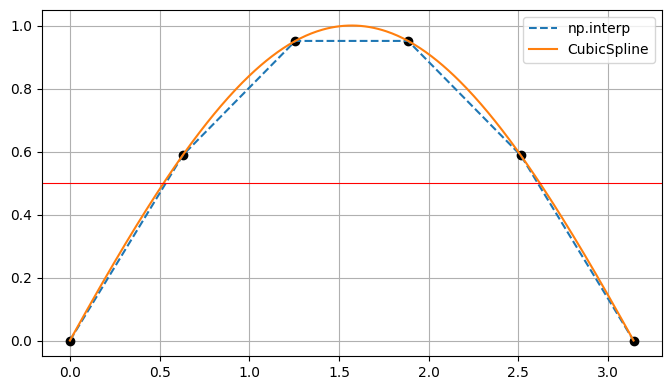

In [4]:
lin_1 = np.interp(1.0, x_table, y_table)
cs_table = CubicSpline(x_table, y_table)
print(lin_1, cs_table(1.0), np.sin(1.0))
print(abs(lin_1 - np.sin(1.0)), abs(cs_table(1.0) - np.sin(1.0)))

x_plot_table = np.linspace(0, np.pi, 400)
plt.plot(x_table, y_table, 'ko')
plt.plot(x_plot_table, np.interp(x_plot_table, x_table, y_table), '--', label='np.interp')
plt.plot(x_plot_table, cs_table(x_plot_table), label='CubicSpline')
plt.axhline(0.5, color='r', lw=0.8)
plt.legend()
plt.show()

> **Для преподавателя.** Разминку студенты делают сами (5–7 минут), затем покажите решение на проекторе. Для первой группы это заодно та практика по интерполяции, которой не хватило на прошлом семинаре.
> 
> Ожидаемый результат: `np.interp` даёт около 0.8027, сплайн около 0.8405, точное значение 0.8415; ошибки около 0.039 и 0.001, то есть сплайн точнее примерно в 40 раз. По графику сплайн равен 0.5 где-то около $x \approx 0.52$.
> 
> На третий вопрос не отвечайте точно: «Пока можем только оценить по графику. К концу семинара научимся находить такие точки с любой точностью» (задача 6). Если кто-то назовёт ответ $\pi/6$ — отлично, но это ответ для синуса, а не для сплайна; разница как раз и есть погрешность интерполяции.
> 
> Типичные ошибки: забыли `import` для `CubicSpline` (импорт есть в ячейке с таблицей), перепутали порядок аргументов `np.interp(x, xp, fp)`.

## 0. Немного Python

Сегодня понадобятся три вещи: передача функции в другую функцию, списки и цикл с досрочным выходом.

**Функция как аргумент.** Функцию можно передать в другую функцию, как обычную переменную (имя без скобок).

In [5]:
def square(x):
    return x**2

def apply_twice(g, x):
    return g(g(x))

print(apply_twice(square, 3))

81


> **Для преподавателя.** Ожидаемый результат: `81`

> **Для преподавателя.** Типичные ошибки: `apply_twice(square(), 3)` или `apply_twice(square(3), 3)` — функцию нужно передавать без скобок. Скобки означают «вызвать функцию», а нам нужно передать её саму.

**Списки и досрочный выход из цикла.** `append` добавляет элемент в конец списка, `values[-1]` — последний элемент, `len(values)` — длина, `break` — досрочный выход из цикла.

In [6]:
values = []
for k in range(20):
    values.append(2**k)
    if values[-1] > 100:
        break

print(values)
print(values[-1], len(values))

[1, 2, 4, 8, 16, 32, 64, 128]
128 8


> **Для преподавателя.** Ожидаемый результат: `[1, 2, 4, 8, 16, 32, 64, 128]` и `128 8`

> **Для преподавателя.** Типичные ошибки:
> - `values = values.append(...)`: метод `append` изменяет список на месте и возвращает `None`, после этого `values` становится `None`;
> - `break` или `if` без отступа внутри цикла;
> - путаница `range(20)` (от 0 до 19) с «от 1 до 20».

## 1. Постановка задачи и локализация корней

Требуется найти $x_*$, такое что $f(x_*) = 0$.

Решение обычно состоит из двух этапов:
1. **Локализация:** найти отрезок $[a, b]$, на котором $f(a)\,f(b) < 0$. Если $f$ непрерывна, на нём есть корень.
2. **Уточнение:** итерационный метод, который приближает корень с нужной точностью.

Весь семинар будем использовать два примера:
- $f(x) = x^2 - 2$, корень $\sqrt{2} \approx 1.41421356$;
- $f(x) = x - \cos x$.

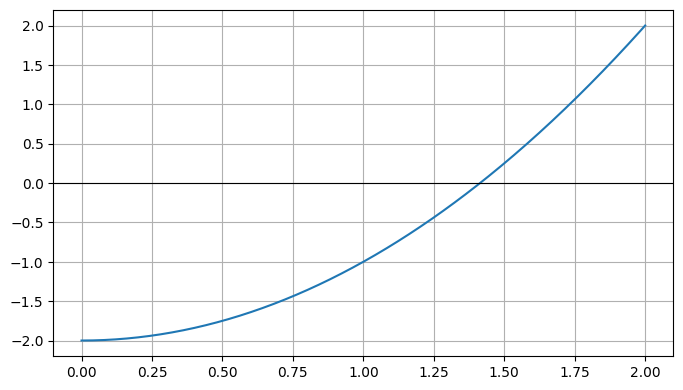

-1.0 2.0


In [7]:
def f_sq(x):
    return x**2 - 2

x_plot = np.linspace(0, 2, 400)
plt.plot(x_plot, f_sq(x_plot))
plt.axhline(0, color='k', lw=0.8)
plt.show()

print(f_sq(1.0), f_sq(2.0))

> **Для преподавателя.** Ожидаемый результат: график пересекает ноль около 1.4, напечатано `-1.0 2.0`. Знаки разные, значит отрезок $[1, 2]$ подходит.

**Мини-задача.** Задайте функцию `f_cos(x)` $= x - \cos x$, постройте её график на $[-2, 2]$ и найдите отрезок длины 1, на концах которого функция имеет разные знаки. Проверьте знаки, напечатав значения на концах.

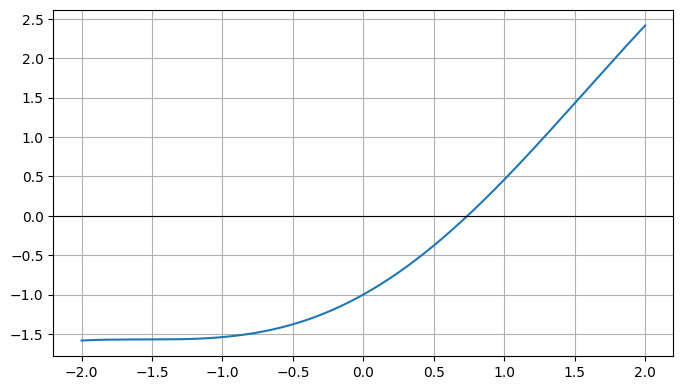

-1.0 0.45969769413186023


In [8]:
def f_cos(x):
    return x - np.cos(x)

x_plot_cos = np.linspace(-2, 2, 400)
plt.plot(x_plot_cos, f_cos(x_plot_cos))
plt.axhline(0, color='k', lw=0.8)
plt.show()

print(f_cos(0.0), f_cos(1.0))

> **Для преподавателя.** Ожидаемый результат: корень между 0 и 1: $f(0) = -1$, $f(1) \approx 0.46$.

> **Для преподавателя.** Функция `f_cos` понадобится до конца семинара, в том числе в готовой ячейке сравнения методов в разделе 6. Убедитесь, что она есть у всех. Типичная ошибка: `cos(x)` вместо `np.cos(x)`.

## 2. Метод деления пополам

**Условия:** $f$ непрерывна на $[a, b]$, $f(a)\,f(b) < 0$.

**Шаг:** $c = \dfrac{a + b}{2}$. Если $f(a)\,f(c) \le 0$, корень на $[a, c]$, иначе на $[c, b]$.

**Оценка:** после $n$ шагов длина отрезка равна $\dfrac{b - a}{2^n}$, поэтому для точности $\varepsilon$ достаточно

$$n \ge \log_2\frac{b - a}{\varepsilon}.$$

| Достоинства | Недостатки |
|---|---|
| Всегда сходится, нужна только непрерывность | Медленный: ошибка уменьшается примерно в 2 раза за шаг (линейная сходимость) |
| Простой | Нужен отрезок со сменой знака; не находит корни чётной кратности |

Функция будет возвращать список всех середин отрезков: последний элемент — ответ, длина списка — число итераций. Ограничение `max_iter` защищает от бесконечного цикла.

In [9]:
def bisection(f, a, b, tol=1e-10, max_iter=100):
    mids = []
    for k in range(max_iter):
        c = (a + b) / 2
        mids.append(c)
        if f(a) * f(c) <= 0:
            b = c
        else:
            a = c
        if b - a < tol:
            break
    return mids

> **Для преподавателя.** Самые частые ошибки в этой функции:
> - `return mids` с отступом внутри цикла: функция завершается после первой итерации и возвращает список из одного элемента;
> - `if b - a < tol: break` вне цикла (без отступа);
> - `else` не на одном уровне с `if`.
> 
> Спросите аудиторию: зачем ограничение `max_iter`, если есть `tol`? Ответ: если `tol` слишком мал (меньше, чем позволяет точность чисел с плавающей точкой) или в коде ошибка, цикл без ограничения никогда не закончится.

In [10]:
mids_sq = bisection(f_sq, 1.0, 2.0, tol=1e-6)
print(mids_sq[-1], len(mids_sq))

1.4142141342163086 20


> **Для преподавателя.** Ожидаемый результат: `1.4142141342163086 20`. По формуле: $\log_2(1/10^{-6}) \approx 19.9$, то есть 20 шагов.

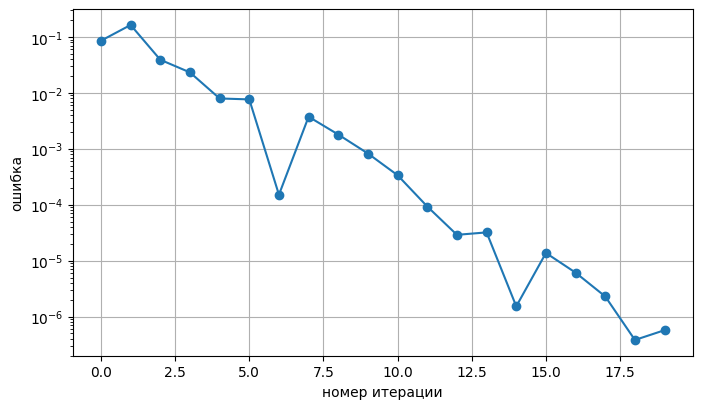

In [11]:
err_bisect_sq = np.abs(np.array(mids_sq) - np.sqrt(2))
plt.semilogy(err_bisect_sq, 'o-')
plt.xlabel('номер итерации')
plt.ylabel('ошибка')
plt.show()

> **Для преподавателя.** Ожидаемый результат: точки в среднем идут вниз вдоль прямой линии, но не монотонно.

> **Для преподавателя.** Вопрос аудитории: почему ошибка убывает не монотонно? Ответ: оценка $(b - a)/2^n$ — это оценка сверху. Середина очередного отрезка может случайно оказаться очень близко к корню, а середина следующего, более короткого отрезка — дальше. Длина отрезка при этом убывает строго в 2 раза.

**Мини-задача.** Найдите корень `f_cos` на $[0, 1]$ с точностью $10^{-8}$. Сначала оцените число итераций по формуле (`np.log2`), затем сравните с длиной списка.

In [12]:
print(np.log2(1.0 / 1e-8))
mids_cos = bisection(f_cos, 0.0, 1.0, tol=1e-8)
print(mids_cos[-1], len(mids_cos))

26.575424759098897
0.7390851303935051 27


> **Для преподавателя.** Ожидаемый результат: оценка $\approx 26.6$, то есть 27 итераций; корень $\approx 0.73908513$.

## 3. Метод простой итерации

Уравнение записывается в виде $x = F(x)$ (поиск **неподвижной точки**), итерации:

$$x_{k+1} = F(x_k).$$

**Теорема о сжатии.** Если $F$ отображает $[a, b]$ в себя и $|F'(x)| \le q < 1$ на $[a, b]$, то неподвижная точка единственна и итерации сходятся к ней из любого $x_0 \in [a, b]$.

- Ошибка уменьшается примерно в $|F'(x_*)|$ раз за шаг: чем меньше, тем быстрее.
- Одно уравнение можно записать в виде $x = F(x)$ многими способами, и сходятся не все.
- Критерий остановки: $|x_{k+1} - x_k| < \varepsilon$ (плюс ограничение на число итераций).

In [13]:
def fixed_point(F, x0, tol=1e-10, max_iter=100):
    xs = [x0]
    for k in range(max_iter):
        xs.append(F(xs[-1]))
        if abs(xs[-1] - xs[-2]) < tol:
            break
    return xs

**Пример.** Уравнение $x^2 = 2$ можно переписать двумя способами:

$$F_1(x) = \frac{2}{x}, \qquad F_2(x) = \frac{1}{2}\left(x + \frac{2}{x}\right).$$

У обеих функций неподвижная точка $\sqrt{2}$.

In [14]:
def F1(x):
    return 2 / x

def F2(x):
    return 0.5 * (x + 2 / x)

xs_F1 = fixed_point(F1, 1.0, max_iter=10)
xs_F2 = fixed_point(F2, 1.0)
print(np.array(xs_F1))
print(np.array(xs_F2))

[1. 2. 1. 2. 1. 2. 1. 2. 1. 2. 1.]
[1.         1.5        1.41666667 1.41421569 1.41421356 1.41421356]


> **Для преподавателя.** Ожидаемый результат: для $F_1$: `1, 2, 1, 2, ...` (не сходится); для $F_2$: `1, 1.5, 1.41666667, 1.41421569, 1.41421356, 1.41421356`.

> **Для преподавателя.** Перед запуском спросите: «Какая из двух функций даст сходимость?». Затем обсудите ответ в следующей ячейке. В методичке эти же две функции приводятся как пример: `F_1` не является сжатием, а `F_2` сходится из любой положительной начальной точки.

**Почему так?** $F_1'(x) = -2/x^2$, в корне $F_1'(\sqrt{2}) = -1$: это не сжатие. $F_2'(x) = \frac{1}{2}\left(1 - \frac{2}{x^2}\right)$, в корне $F_2'(\sqrt{2}) = 0$.

**Наглядно** (просто запустите). Итерации изображаются «лестницей»: от точки на графике $y = F(x)$ горизонтально к прямой $y = x$, затем вертикально снова к графику.

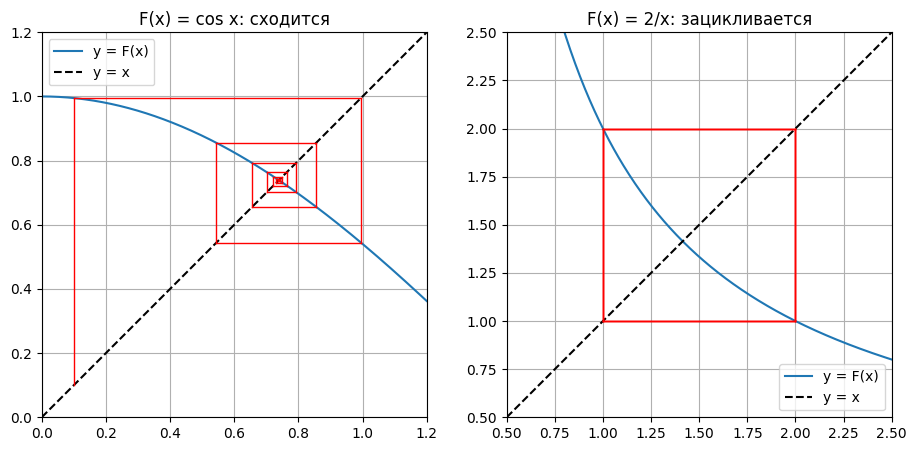

In [15]:
def cobweb(F, x0, n_steps, x_min, x_max, ax):
    x_line = np.linspace(x_min, x_max, 400)
    ax.plot(x_line, F(x_line), label='y = F(x)')
    ax.plot(x_line, x_line, 'k--', label='y = x')
    x = x0
    for k in range(n_steps):
        y = F(x)
        ax.plot([x, x], [x, y], 'r', lw=1)
        ax.plot([x, y], [y, y], 'r', lw=1)
        x = y
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(x_min, x_max)
    ax.set_aspect('equal')
    ax.legend()


fig, ax = plt.subplots(1, 2, figsize=(11, 5))
cobweb(np.cos, 0.1, 20, 0.0, 1.2, ax[0])
ax[0].set_title('F(x) = cos x: сходится')
cobweb(F1, 1.0, 6, 0.5, 2.5, ax[1])
ax[1].set_title('F(x) = 2/x: зацикливается')
plt.show()

> **Для преподавателя.** Как читать диаграмму: начинаем на оси x в точке $x_0$, поднимаемся вертикально до графика $F$ (получаем $F(x_0) = x_1$), идём горизонтально до прямой $y = x$ (переносим $x_1$ на ось x), снова вертикально до графика и т. д. Если $|F'| < 1$ у неподвижной точки, лестница «закручивается» внутрь; у $F = 2/x$ наклон в точке пересечения равен $-1$, и получается замкнутый квадрат.

**Мини-задача.** Уравнение $x = \cos x$ можно записать в виде $x = F(x)$, например, так:

$$F_a(x) = \cos x, \qquad F_b(x) = \frac{x + \cos x}{2}, \qquad F_c(x) = 2x - \cos x.$$

1. Для каждой функции запустите `fixed_point` из $x_0 = 1$ с `tol=1e-8` и напечатайте число итераций и последнее значение.
2. Вычислите $|F'(x_*)|$ для каждой из функций при $x_* \approx 0.739$ и объясните результат.

In [16]:
def F_a(x):
    return np.cos(x)

def F_b(x):
    return (x + np.cos(x)) / 2

def F_c(x):
    return 2 * x - np.cos(x)

for F in [F_a, F_b, F_c]:
    xs = fixed_point(F, 1.0, tol=1e-8)
    print(len(xs) - 1, xs[-1])

x_star = 0.739
print(abs(-np.sin(x_star)), abs((1 - np.sin(x_star)) / 2), abs(2 + np.sin(x_star)))

46 0.7390851366465718
11 0.7390851336142326
100 9.324551008226046e+29
0.6735491060485659 0.16322544697571706 2.673549106048566


> **Для преподавателя.** Ожидаемый результат: $F_a$: 46 итераций, $F_b$: 11 итераций, $F_c$: значения растут (за 100 итераций до $\sim 10^{29}$). Производные: $|F_a'| \approx 0.67$, $|F_b'| \approx 0.16$, $|F_c'| \approx 2.67$.

> **Для преподавателя.** Обсуждение: чем меньше $|F'(x_*)|$, тем быстрее сходимость: у $F_b$ ошибка уменьшается примерно в 6 раз за шаг, у $F_a$ — примерно в 1.5 раза. У $F_c$ $|F'| > 1$, ошибка растёт. Все три функции имеют одну и ту же неподвижную точку, то есть это одно и то же уравнение. Если кто-то получил у $F_c$ сообщение о переполнении (`overflow`), это тоже признак расходимости.

## 4. Метод Ньютона

Следующее приближение — точка пересечения касательной в $x_k$ с осью абсцисс:

$$x_{k+1} = x_k - \frac{f(x_k)}{f'(x_k)}.$$

- Это простая итерация с $F(x) = x - \dfrac{f(x)}{f'(x)}$. Для простого корня $F'(x_*) = 0$, поэтому сходимость **квадратичная**:
$$x_{k+1} - x_* \approx \frac{f''(x_*)}{2f'(x_*)}(x_k - x_*)^2,$$
то есть число верных знаков примерно удваивается за шаг.
- Для корня кратности $\alpha$: $F'(x_*) = \dfrac{\alpha - 1}{\alpha}$, сходимость линейная.
- Недостатки: нужна производная; сходимость гарантирована только при $x_0$, достаточно близком к корню.

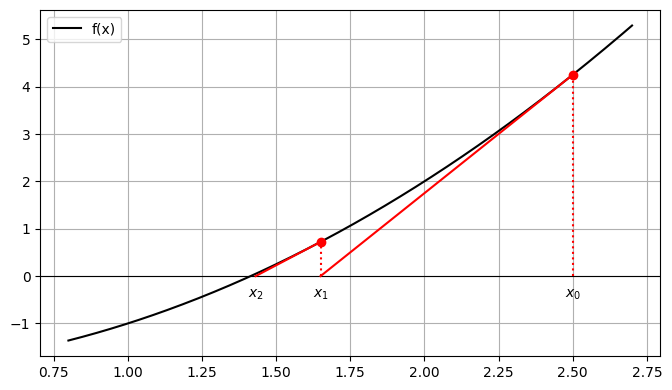

In [17]:
# Иллюстрация: два шага метода Ньютона для f(x) = x^2 - 2 из x0 = 2.5 (просто запустите)
x_ill = np.linspace(0.8, 2.7, 400)
plt.plot(x_ill, f_sq(x_ill), 'k', label='f(x)')
plt.axhline(0, color='k', lw=0.8)
x_k = 2.5
for k in range(2):
    x_next = x_k - f_sq(x_k) / (2 * x_k)
    plt.plot([x_k, x_next], [f_sq(x_k), 0], 'r')
    plt.plot([x_k, x_k], [0, f_sq(x_k)], 'r:')
    plt.plot(x_k, f_sq(x_k), 'ro')
    plt.annotate(f'$x_{k}$', (x_k, 0), textcoords='offset points', xytext=(0, -15), ha='center')
    x_k = x_next
plt.annotate('$x_2$', (x_k, 0), textcoords='offset points', xytext=(0, -15), ha='center')
plt.legend()
plt.show()

In [18]:
def newton(f, df, x0, tol=1e-12, max_iter=50):
    xs = [x0]
    for k in range(max_iter):
        x = xs[-1]
        xs.append(x - f(x) / df(x))
        if abs(xs[-1] - xs[-2]) < tol:
            break
    return xs

> **Для преподавателя.** Покажите студентам, что функция отличается от `fixed_point` одной строкой. Можно скопировать `fixed_point` и изменить её вживую: это быстрее и наглядно показывает, что Ньютон — частный случай простой итерации.

In [19]:
def df_sq(x):
    return 2 * x

xs_newton_sq = newton(f_sq, df_sq, 1.0)
print(np.array(xs_newton_sq))

[1.         1.5        1.41666667 1.41421569 1.41421356 1.41421356
 1.41421356]


> **Для преподавателя.** Ожидаемый результат: `1, 1.5, 1.41666667, 1.41421569, 1.41421356, ...`

**Вопрос.** Сравните с `xs_F2` из раздела 3. Почему получились те же самые числа? Подставьте $f(x) = x^2 - 2$ в формулу Ньютона.

Посмотрим на ошибки.

> **Для преподавателя.** Ответ на вопрос: $x - \dfrac{x^2 - 2}{2x} = \dfrac{2x^2 - x^2 + 2}{2x} = \dfrac{x^2 + 2}{2x} = \dfrac{1}{2}\left(x + \dfrac{2}{x}\right) = F_2(x)$. То есть «удачная» функция $F_2$ из раздела 3 — это и есть метод Ньютона для $x^2 - 2$. Отсюда и $F_2'(\sqrt{2}) = 0$: у метода Ньютона $F'(x_*) = 0$ для простого корня. Эта формула известна как формула Герона для вычисления квадратного корня.

In [20]:
err_newton_sq = np.abs(np.array(xs_newton_sq) - np.sqrt(2))
print(err_newton_sq)

[4.14213562e-01 8.57864376e-02 2.45310429e-03 2.12390141e-06
 1.59472435e-12 0.00000000e+00 2.22044605e-16]


> **Для преподавателя.** Ожидаемый результат: `4.1e-01, 8.6e-02, 2.5e-03, 2.1e-06, 1.6e-12`, дальше значения порядка $10^{-16}$ или ноль (это ошибки округления). Показатель степени примерно удваивается: число верных знаков удваивается за шаг.

> **Для преподавателя.** Если показатели степени не очевидны, переведите в число верных знаков: ошибки $10^{-1}, 10^{-2}, 10^{-3}, 10^{-6}, 10^{-12}$ — верных знаков 1, 2, 3, 6, 12.

**Мини-задача.** Найдите корень `f_cos` методом Ньютона из $x_0 = 1$. Для этого задайте производную `df_cos(x)`. Сколько понадобилось итераций?

In [21]:
def df_cos(x):
    return 1 + np.sin(x)

xs_newton_cos = newton(f_cos, df_cos, 1.0)
print(np.array(xs_newton_cos))
print(len(xs_newton_cos) - 1)

[1.         0.75036387 0.73911289 0.73908513 0.73908513 0.73908513]
5


> **Для преподавателя.** Ожидаемый результат: 5 итераций, корень $0.7390851332151607$.

### Когда метод Ньютона не работает (просто запустите)

**Зацикливание.** $f(x) = x^3 - 2x + 2$, $x_0 = 0$:

In [22]:
xs_cycle = newton(lambda x: x**3 - 2*x + 2, lambda x: 3*x**2 - 2, 0.0, max_iter=8)
print(np.array(xs_cycle))

[0. 1. 0. 1. 0. 1. 0. 1. 0.]


**Расходимость.** $f(x) = \operatorname{arctg} x$ (корень $x_* = 0$), $x_0 = 1.5$:

In [23]:
xs_atan = newton(np.arctan, lambda x: 1 / (1 + x**2), 1.5, max_iter=6)
print(np.array(xs_atan))

[ 1.50000000e+00 -1.69407960e+00  2.32112696e+00 -5.11408784e+00
  3.22956839e+01 -1.57531695e+03  3.89497601e+06]


**Кратный корень.** $f(x) = (x - 1)^2$, $x_0 = 2$. Деление пополам здесь неприменимо: знак функции не меняется. Ньютон сходится, но линейно:

In [24]:
xs_double = newton(lambda x: (x - 1)**2, lambda x: 2 * (x - 1), 2.0, max_iter=100)
err_double = np.abs(np.array(xs_double) - 1)
print('итераций:', len(xs_double) - 1)
print('первые ошибки:', err_double[:6])
print('отношения соседних ошибок:', err_double[1:6] / err_double[:5])

итераций: 40
первые ошибки: [1.      0.5     0.25    0.125   0.0625  0.03125]
отношения соседних ошибок: [0.5 0.5 0.5 0.5 0.5]


Отношение ошибок равно $1/2 = (\alpha - 1)/\alpha$ при $\alpha = 2$.

> **Для преподавателя.** Комментарии к демонстрациям:
> - зацикливание: касательная из $x = 0$ попадает в $x = 1$, а касательная из $x = 1$ возвращает в $x = 0$; Ньютон не обязан сходиться даже при существующем корне (корень есть, около $-1.77$);
> - арктангенс: при $|x_0| \gtrsim 1.39$ касательная настолько пологая, что «перелетает» корень всё дальше и дальше; из $x_0 = 1$ метод сходится;
> - кратный корень: по формуле $F'(x_*) = (\alpha - 1)/\alpha$ из теории. Критерий остановки $|x_{k+1} - x_k| < 10^{-12}$ здесь срабатывает только через 40 итераций.

## 5. Метод секущих

Производная заменяется разностным отношением по двум последним приближениям:

$$x_{k+1} = x_k - f(x_k)\,\frac{x_k - x_{k-1}}{f(x_k) - f(x_{k-1})}.$$

- Нужны две начальные точки, производная не нужна.
- Порядок сходимости $\dfrac{1 + \sqrt{5}}{2} \approx 1.618$: ниже, чем у Ньютона, но выше линейного.
- За шаг одно новое вычисление $f$ (у Ньютона $f$ и $f'$), поэтому часто метод секущих выгоднее.

In [25]:
def secant(f, x0, x1, tol=1e-12, max_iter=50):
    xs = [x0, x1]
    for k in range(max_iter):
        x_prev, x_cur = xs[-2], xs[-1]
        f_prev, f_cur = f(x_prev), f(x_cur)
        xs.append(x_cur - f_cur * (x_cur - x_prev) / (f_cur - f_prev))
        if abs(xs[-1] - xs[-2]) < tol:
            break
    return xs

In [26]:
xs_secant_sq = secant(f_sq, 1.0, 2.0)
print(np.abs(np.array(xs_secant_sq) - np.sqrt(2)))

[4.14213562e-01 5.85786438e-01 8.08802290e-02 1.42135624e-02
 4.20583968e-04 2.12389823e-06 3.15774740e-10 2.22044605e-16
 0.00000000e+00]


> **Для преподавателя.** Ожидаемый результат: `4.1e-01, 5.9e-01, 8.1e-02, 1.4e-02, 4.2e-04, 2.1e-06, 3.2e-10`, затем порядка $10^{-16}$.

> **Для преподавателя.** Если у студента `ZeroDivisionError`, скорее всего, он передал две одинаковые начальные точки (тогда $f(x_k) - f(x_{k-1}) = 0$). Сравните с Ньютоном: у секущих на 1–2 итерации больше, но производная не нужна.

**Мини-задача.** Найдите корень `f_cos` методом секущих из точек $0$ и $1$. Сколько понадобилось итераций (не считая двух начальных точек)?

In [27]:
xs_secant_cos = secant(f_cos, 0.0, 1.0)
print(xs_secant_cos[-1], len(xs_secant_cos) - 2)

0.7390851332151607 6


> **Для преподавателя.** Ожидаемый результат: 6 итераций, корень $0.7390851332151607$.

## 6. Сравнение методов. Метод Брента и `scipy`

Ошибки всех методов для уравнения $x = \cos x$ на одном графике (просто запустите; используются ваши функции).

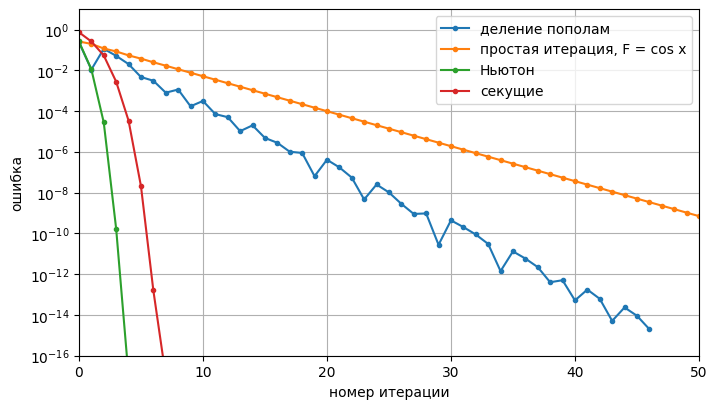

In [28]:
from scipy.optimize import brentq

root_cos = brentq(f_cos, 0.0, 1.0, xtol=1e-15)

def df_cos_ref(x):
    return 1 + np.sin(x)

results = {
    'деление пополам': bisection(f_cos, 0.0, 1.0, tol=1e-14),
    'простая итерация, F = cos x': fixed_point(np.cos, 1.0, tol=1e-14),
    'Ньютон': newton(f_cos, df_cos_ref, 1.0),
    'секущие': secant(f_cos, 0.0, 1.0),
}
for name, xs in results.items():
    err = np.abs(np.array(xs) - root_cos) + 1e-17
    plt.semilogy(err, 'o-', ms=3, label=name)
plt.ylim(1e-16, 10)
plt.xlim(0, 50)
plt.xlabel('номер итерации')
plt.ylabel('ошибка')
plt.legend()
plt.show()

> **Для преподавателя.** Эта ячейка использует функции `f_cos`, `bisection`, `fixed_point`, `newton` и `secant`, написанные студентами. Если у кого-то она падает с ошибкой, проблема в одной из этих функций; не тратьте на это время семинара, пусть студент посмотрит график на проекторе.
> 
> Как читать график: у деления пополам и простой итерации точки лежат около прямых (линейная сходимость: ошибка умножается примерно на одно и то же число за шаг, 1/2 и 0.67). У Ньютона и секущих наклон становится всё круче: сходимость сверхлинейная.

Линейная сходимость в логарифмическом масштабе — прямая линия. У Ньютона и секущих график круто уходит вниз.

### Метод Брента

Объединяет надёжность деления пополам и скорость интерполяционных методов:
- всегда хранится отрезок со сменой знака;
- на каждом шаге пробуется «быстрый» шаг: секущая или обратная квадратичная интерполяция;
- если быстрый шаг выводит за отрезок или сокращает его слишком медленно, выполняется шаг деления пополам.

Итог: сходимость гарантирована, как у деления пополам, а вблизи корня скорость как у интерполяционных методов.

**Обратная квадратичная интерполяция:** по трём последним точкам строится многочлен второй степени $x = p(y)$ ($x$ как функция от $y$), новое приближение $x_{\text{new}} = p(0)$:

$$x_{\text{new}} = \frac{x_0 f_1 f_2}{(f_0 - f_1)(f_0 - f_2)} + \frac{x_1 f_0 f_2}{(f_1 - f_0)(f_1 - f_2)} + \frac{x_2 f_0 f_1}{(f_2 - f_0)(f_2 - f_1)}.$$

В `scipy` метод Брента реализован функцией `scipy.optimize.brentq(f, a, b)`. На практике для одного уравнения с известным отрезком смены знака обычно используют её. Метод Ньютона и метод секущих есть в `scipy.optimize.newton`.

In [29]:
root_brent, info = brentq(f_cos, 0.0, 1.0, full_output=True)
print(root_brent, info.iterations, info.function_calls)

0.7390851332151559 7 8


> **Для преподавателя.** Ожидаемый результат: `0.7390851332151559 7 8`. Делению пополам для такой же точности ($2 \cdot 10^{-12}$) понадобилось бы 39 итераций.

> **Для преподавателя.** Обратная квадратичная интерполяция связана с прошлым семинаром: это интерполяционный многочлен в форме Лагранжа, только построенный для обратной функции $x(y)$. В отличие от метода парабол, не нужно решать квадратное уравнение и не возникают комплексные корни.
> 
> Типичная ошибка при использовании `brentq`: `ValueError: f(a) and f(b) must have different signs` — на концах отрезка функция одного знака, отрезок выбран неправильно.

**Мини-задача.** Найдите с помощью `brentq` корень $\operatorname{arctg} x$ на отрезке $[-1, 1.5]$ — функции, на которой метод Ньютона из $x_0 = 1.5$ расходился.

In [30]:
print(brentq(np.arctan, -1.0, 1.5))

3.887777003140057e-17


> **Для преподавателя.** Ожидаемый результат: число порядка $10^{-17}$, то есть ноль с точностью до округления.

---
## 7. Задачи

### Основные

**Задача 1.** Найдите корень уравнения $e^x = 2$ методом деления пополам на $[0, 1]$ и сравните с `np.log(2)`.

In [31]:
def f_exp(x):
    return np.exp(x) - 2

mids_exp = bisection(f_exp, 0.0, 1.0)
print(mids_exp[-1], np.log(2))

0.6931471805437468 0.6931471805599453


**Задача 2.** Уравнение $x^3 - x - 1 = 0$: постройте график, выберите отрезок со сменой знака, найдите корень делением пополам и проверьте ответ с помощью `brentq`.

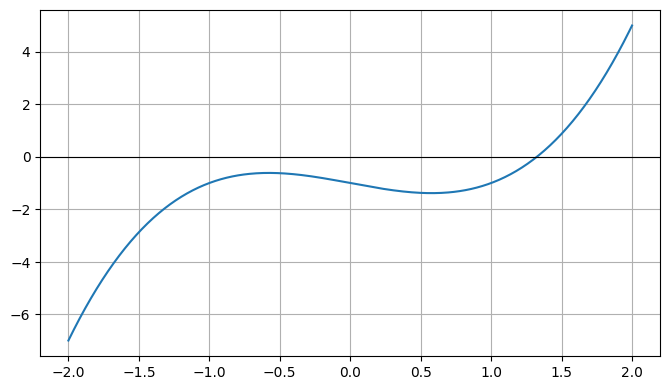

1.324717957235407 1.324717957244746


In [32]:
def f_cubic(x):
    return x**3 - x - 1

x_plot_cubic = np.linspace(-2, 2, 400)
plt.plot(x_plot_cubic, f_cubic(x_plot_cubic))
plt.axhline(0, color='k', lw=0.8)
plt.show()

print(bisection(f_cubic, 1.0, 2.0)[-1], brentq(f_cubic, 1.0, 2.0))

**Задача 3.** Уравнение $\sin x = 0.5x$ имеет три корня. Постройте график $f(x) = \sin x - 0.5x$ на $[-3, 3]$, выделите три отрезка, каждый из которых содержит ровно один корень, и найдите все корни делением пополам.

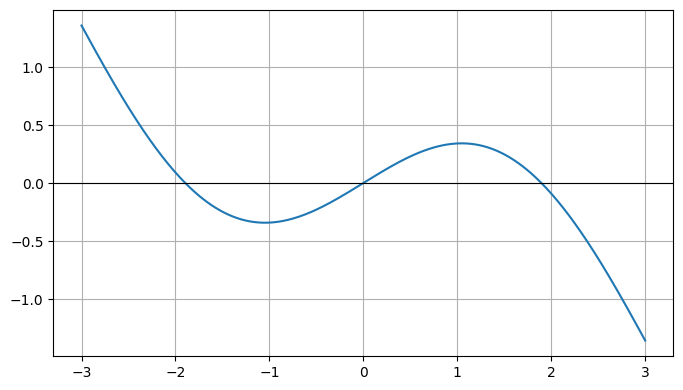

-1.8954942670534365
-5.820766091346741e-11
1.8954942670534365


In [33]:
def f_sin(x):
    return np.sin(x) - 0.5 * x

x_plot_sin = np.linspace(-3, 3, 400)
plt.plot(x_plot_sin, f_sin(x_plot_sin))
plt.axhline(0, color='k', lw=0.8)
plt.show()

for a_k, b_k in [(-3.0, -1.0), (-0.5, 0.5), (1.0, 3.0)]:
    print(bisection(f_sin, a_k, b_k)[-1])

> **Для преподавателя.** Ловушка в задаче 3: если студент возьмёт отрезок, у которого корень на конце, например $[0, 2]$, то $f(0) = 0$, условие $f(a)f(c) \le 0$ выполняется всегда, и метод сойдётся к нулю, а не к корню $1.895$. Это хороший повод обсудить, почему отрезки нужно выбирать так, чтобы в каждом был ровно один корень и он был внутри.

**Задача 4.** Вычислите $\sqrt[3]{10}$ методом Ньютона. Какое уравнение нужно решать? Сравните с `10 ** (1/3)`.

In [34]:
def f_cbrt(x):
    return x**3 - 10

def df_cbrt(x):
    return 3 * x**2

print(newton(f_cbrt, df_cbrt, 2.0)[-1], 10 ** (1 / 3))

2.154434690031884 2.154434690031884


**Задача 5.** Для уравнения $x^3 - x - 1 = 0$ сравните число итераций деления пополам на $[1, 2]$ и метода Ньютона из $x_0 = 1.5$ при одинаковой точности `tol=1e-10`.

In [35]:
def df_cubic(x):
    return 3 * x**2 - 1

print(len(bisection(f_cubic, 1.0, 2.0, tol=1e-10)))
print(len(newton(f_cubic, df_cubic, 1.5, tol=1e-10)) - 1)

34
5


**Задача 6. Возвращаемся к разминке.** Найдите $x$, при котором сплайн `cs_table` из разминки равен $0.5$: решите уравнение $S(x) - 0.5 = 0$ делением пополам и с помощью `brentq` (отрезок выберите по таблице или по графику). Сравните ответ с $\pi/6$. Почему ответы немного отличаются?

In [36]:
def f_table(x):
    return cs_table(x) - 0.5

print(bisection(f_table, 0.0, x_table[1])[-1])
print(brentq(f_table, 0.0, x_table[1]))
print(np.pi / 6)

0.5225306473457079
0.5225306473216024
0.5235987755982988


*Ответы:* 1) $0.69314718$; 2) $1.32471796$; 3) $-1.89549427$, $0$, $1.89549427$; 4) $2.15443469$; 5) 34 и 5 итераций; 6) около $0.5225$ против $\pi/6 \approx 0.5236$. Метод поиска корня даёт корень уравнения для сплайна с точностью $10^{-10}$, а отличие от $\pi/6$ — это погрешность интерполяции: сплайн по 6 точкам не совпадает с синусом точно. Главная мысль: сплайн — обычная функция, к ней применимы все методы этого семинара.

### Для тех, кто справился быстрее

**Задача 7. Уравнение Кеплера.** Положение тела на эллиптической орбите в момент времени задаётся эксцентрической аномалией $E$, которая находится из уравнения

$$E - e\sin E = M,$$

где $e$ — эксцентриситет орбиты, $M$ — средняя аномалия (пропорциональна времени). Найдите $E$ методом Ньютона при $e = 0.5$, $M = 1$ (начальное приближение $E_0 = M$).

In [37]:
def f_kepler(E):
    return E - 0.5 * np.sin(E) - 1.0

def df_kepler(E):
    return 1 - 0.5 * np.cos(E)

xs_kepler = newton(f_kepler, df_kepler, 1.0)
print(xs_kepler[-1], len(xs_kepler) - 1)

1.4987011335178484 5


*Ответ:* $E \approx 1.49870113$, 5 итераций.

**Задача 8. Задача Стефана.** При плавлении вещества фронт плавления движется по закону $s(t) = 2\lambda\sqrt{a t}$, где $a$ — температуропроводность, а безразмерный параметр $\lambda$ находится из уравнения

$$\lambda\, e^{\lambda^2} \operatorname{erf}\lambda = \frac{\mathrm{St}}{\sqrt{\pi}}.$$

Здесь $\mathrm{St}$ — число Стефана (отношение теплоты нагрева к теплоте плавления), $\operatorname{erf}$ — функция ошибок (`from scipy.special import erf`).

1. Найдите $\lambda$ для $\mathrm{St} = 0.1,\ 0.5,\ 1,\ 2$ любым методом.
2. При малых $\lambda$ имеем $e^{\lambda^2} \approx 1$, $\operatorname{erf}\lambda \approx 2\lambda/\sqrt{\pi}$, откуда $\lambda \approx \sqrt{\mathrm{St}/2}$. Сравните с найденными значениями. При каких St приближение хорошее?

In [38]:
from scipy.special import erf

for St in [0.1, 0.5, 1.0, 2.0]:
    def f_stefan(lam):
        return lam * np.exp(lam**2) * erf(lam) - St / np.sqrt(np.pi)
    lam = bisection(f_stefan, 0.0, 3.0)[-1]
    print(St, lam, np.sqrt(St / 2))

0.1 0.22001627276767977 0.22360679774997896
0.5 0.464785920601571 0.5
1.0 0.6200626333302353 0.7071067811865476
2.0 0.8006013628619257 1.0


*Ответ:* $\lambda \approx 0.2200,\ 0.4648,\ 0.6201,\ 0.8006$; приближение $\sqrt{\mathrm{St}/2}$ даёт $0.2236,\ 0.5,\ 0.7071,\ 1.0$ и хорошо работает только при малых St.

---
## Итоги

| Метод | Что нужно | Сходимость | Надёжность |
|---|---|---|---|
| Деление пополам | отрезок со сменой знака | линейная, в 2 раза за шаг | всегда сходится |
| Простая итерация | форма $x = F(x)$ с $\lvert F'\rvert < 1$ | линейная, в $\lvert F'(x_*)\rvert$ раз за шаг | зависит от выбора $F$ |
| Ньютон | $f'$, хорошее начальное приближение | квадратичная (простой корень) | локальная |
| Секущие | две начальные точки | порядок $\approx 1.618$ | локальная |
| Брент | отрезок со сменой знака | быстрая вблизи корня | всегда сходится |

> **Для преподавателя.** В итогах стоит проговорить общий практический вывод: сначала график и локализация корня, затем надёжный метод (деление пополам или Брент), а если нужна скорость и есть производная — Ньютон с хорошим начальным приближением.

---
## 8. Домашнее задание

### Основная часть

**ДЗ 1. Кратный корень.** Для $f(x) = (x - 1)^3(x + 2)$:
1. Найдите корень $x_* = 1$ методом Ньютона из $x_0 = 2$. Сколько понадобилось итераций? Чему равно отношение соседних ошибок и как оно связано с кратностью корня?
2. Модифицированный метод Ньютона для корня кратности $\alpha$: $x_{k+1} = x_k - \alpha\dfrac{f(x_k)}{f'(x_k)}$. Реализуйте его и сравните число итераций.
3. Можно ли найти этот корень делением пополам? Почему?

**ДЗ 2. Уравнение Кеплера.** Для $e = 0.5$ найдите $E(M)$ для 50 значений $M$ на $[0, 2\pi]$ и постройте график. Затем повторите для $e = 0.99$ (начальное приближение $E_0 = M$, `max_iter=100`) и напечатайте число итераций для каждого $M$. При каких $M$ метод работает плохо и почему? Подсказка: посмотрите на $f'(E) = 1 - e\cos E$ вблизи $E = 0$. Проверьте, помогает ли начальное приближение $E_0 = \pi$. Как можно использовать `brentq` (какой отрезок взять)?

**ДЗ 3. Максимум плотности воды** (продолжение ДЗ первого семинара). Постройте по таблице плотности воды кубический сплайн и найдите максимум плотности как корень $S'(T) = 0$ своими методами: делением пополам и методом Ньютона (производные сплайна: `cs(T, 1)` и `cs(T, 2)`). Сравните с результатом `brentq`.

### Задачи повышенной сложности (по желанию)

**ДЗ 4. Фрактал Ньютона.** Уравнение $z^3 = 1$ имеет три комплексных корня. Возьмите сетку начальных точек $z_0 = x + iy$, $x, y \in [-2, 2]$ (например, 500 × 500), выполните 30 итераций метода Ньютона сразу для всех точек (с массивами `numpy` это делается без циклов по точкам) и раскрасьте каждую начальную точку в цвет корня, к которому она сошлась (`plt.imshow`). Объясните, что видно на картинке.

**ДЗ 5. Поиск всех корней.** Многочлен $P(x) = x^4 - 10x^3 + 35x^2 - 50x + 24$ имеет четыре корня. Найдите их методом удаления корней (см. дополнительный раздел): после нахождения корня $x_1$ ищите корни функции $P(x)/(x - x_1)$ и т. д. Сравните с `np.roots`.

---
## Дополнительно

**Метод парабол.** Через три последние точки $x_{k-2}, x_{k-1}, x_k$ проводится интерполяционная парабола (в форме Ньютона)

$$p_2(x) = f_k + f[x_{k-1}, x_k](x - x_k) + f[x_{k-2}, x_{k-1}, x_k](x - x_k)(x - x_{k-1}),$$

и в качестве $x_{k+1}$ берётся её корень, ближайший к $x_k$. Порядок сходимости выше, чем у секущих, но ниже, чем у Ньютона. Даже при вещественных $f$ и начальных точках метод может привести к комплексному корню, поэтому удобен для поиска корней многочленов.

**Поиск всех корней (удаление корней).** Если найден корень $x_1$ функции $f$, то остальные корни $f$ — это корни функции

$$f_1(x) = \frac{f(x)}{x - x_1}.$$

Найдя корень $x_2$ функции $f_1$, переходим к $f_2(x) = \dfrac{f(x)}{(x - x_1)(x - x_2)}$ и т. д. Поскольку корни известны лишь приближённо, ошибки накапливаются; поэтому найденное по вспомогательной функции приближение уточняют несколькими итерациями по исходной функции $f$.

---
## Решения домашнего задания (только в версии преподавателя)

**ДЗ 1. Кратный корень.**

In [39]:
def f_mult(x):
    return (x - 1)**3 * (x + 2)

def df_mult(x):
    return 3 * (x - 1)**2 * (x + 2) + (x - 1)**3

xs_mult = newton(f_mult, df_mult, 2.0, max_iter=200)
err_mult = np.abs(np.array(xs_mult) - 1)
print('Ньютон: итераций', len(xs_mult) - 1)
print('отношения ошибок:', err_mult[1:8] / err_mult[:7])


def newton_modified(f, df, x0, alpha, tol=1e-12, max_iter=50):
    xs = [x0]
    for k in range(max_iter):
        x = xs[-1]
        if f(x) == 0:          # попали точно в корень
            break
        xs.append(x - alpha * f(x) / df(x))
        if abs(xs[-1] - xs[-2]) < tol:
            break
    return xs

xs_mod = newton_modified(f_mult, df_mult, 2.0, alpha=3)
print('модифицированный Ньютон: итераций', len(xs_mod) - 1)
print('ошибки:', np.abs(np.array(xs_mod) - 1))
print('деление пополам:', bisection(f_mult, 0.0, 2.0)[-1])

Ньютон: итераций 67
отношения ошибок: [0.69230769 0.68627451 0.68119552 0.67714613 0.67406309 0.67180085
 0.670187  ]
модифицированный Ньютон: итераций 5
ошибки: [1.00000000e+00 7.69230769e-02 6.35727908e-04 4.48928683e-08
 2.22044605e-16 0.00000000e+00]
деление пополам: 0.9999999999417923


Обычный Ньютон: 67 итераций, отношение ошибок стремится к $2/3 = (\alpha - 1)/\alpha$ при $\alpha = 3$. Модифицированный: 5 итераций, квадратичная сходимость восстанавливается. Деление пополам применимо, потому что кратность нечётная и функция меняет знак в корне (в отличие от $(x - 1)^2$).

**ДЗ 2. Уравнение Кеплера.**

e = 0.5: максимум итераций при E0 = M: 5, при E0 = pi: 7
e = 0.99: максимум итераций при E0 = M: 100, при E0 = pi: 11


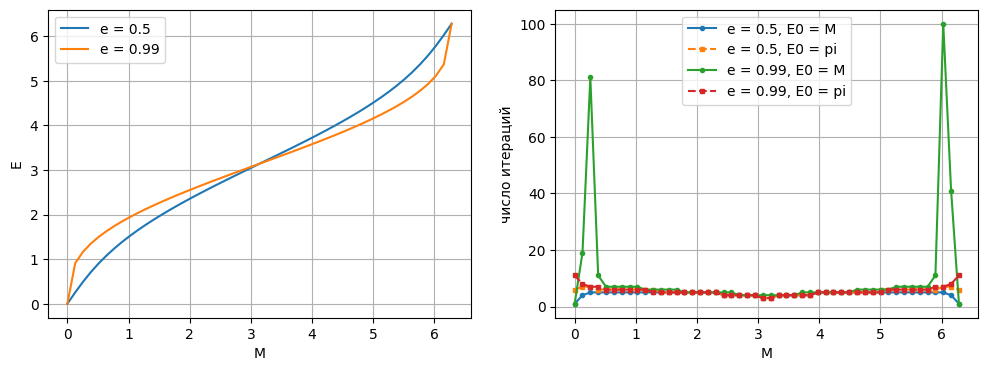

In [40]:
M_grid = np.linspace(0, 2 * np.pi, 50)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for e in [0.5, 0.99]:
    E_vals, iters_M, iters_pi = [], [], []
    for M in M_grid:
        f_k = lambda E: E - e * np.sin(E) - M
        df_k = lambda E: 1 - e * np.cos(E)
        xs_M = newton(f_k, df_k, M, max_iter=100)
        xs_pi = newton(f_k, df_k, np.pi, max_iter=100)
        E_vals.append(brentq(f_k, 0.0, 2 * np.pi))
        iters_M.append(len(xs_M) - 1)
        iters_pi.append(len(xs_pi) - 1)
    ax[0].plot(M_grid, E_vals, label=f'e = {e}')
    ax[1].plot(M_grid, iters_M, 'o-', ms=3, label=f'e = {e}, E0 = M')
    ax[1].plot(M_grid, iters_pi, 's--', ms=3, label=f'e = {e}, E0 = pi')
    print(f'e = {e}: максимум итераций при E0 = M: {max(iters_M)}, при E0 = pi: {max(iters_pi)}')
ax[0].set_xlabel('M'); ax[0].set_ylabel('E'); ax[0].legend()
ax[1].set_xlabel('M'); ax[1].set_ylabel('число итераций'); ax[1].legend()
plt.show()

При $e = 0.99$ и $M$ вблизи $0$ и $2\pi$ начальное приближение $E_0 = M$ работает плохо: $f'(E) = 1 - e\cos E \approx 0.01$ около $E = 0$, касательная почти горизонтальная, и метод делает огромные шаги (десятки итераций, при некоторых $M$ не сходится за 100). Начальное приближение $E_0 = \pi$ даёт сходимость не более чем за 11 итераций. Для `brentq` подходит отрезок $[0, 2\pi]$: $f(0) = -M \le 0$, $f(2\pi) = 2\pi - M \ge 0$.

**ДЗ 3. Максимум плотности воды.**

In [41]:
from scipy.interpolate import CubicSpline

T_tab = np.arange(0, 21, 2.0)
rho_tab = np.array([999.84, 999.94, 999.97, 999.94, 999.85, 999.70, 999.50, 999.24, 998.94, 998.60, 998.21])
cs_rho = CubicSpline(T_tab, rho_tab)

def drho(T):
    return cs_rho(T, 1)

def d2rho(T):
    return cs_rho(T, 2)

print('деление пополам:', bisection(drho, 1.0, 8.0)[-1])
print('Ньютон:         ', newton(drho, d2rho, 4.0)[-1])
print('brentq:         ', brentq(drho, 1.0, 8.0))

деление пополам: 3.969253170529555
Ньютон:          3.969253170522751
brentq:          3.9692531705231


Все три метода дают $T_{\max} \approx 3.97$ °C.

**ДЗ 4. Фрактал Ньютона.**

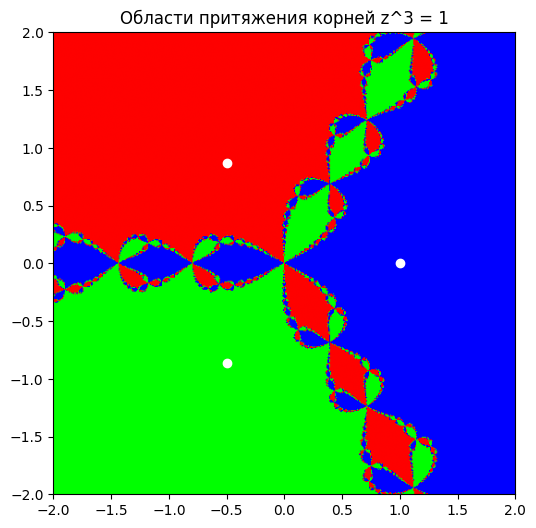

In [42]:
x_grid = np.linspace(-2, 2, 500)
X, Y = np.meshgrid(x_grid, x_grid)
Z = X + 1j * Y
with np.errstate(divide='ignore', invalid='ignore'):
    for k in range(30):
        Z = Z - (Z**3 - 1) / (3 * Z**2)
roots3 = np.exp(2j * np.pi * np.arange(3) / 3)
basin = np.argmin(np.abs(Z[..., None] - roots3), axis=-1)

plt.figure(figsize=(6, 6))
plt.imshow(basin, extent=[-2, 2, -2, 2], origin='lower', cmap='brg')
plt.plot(roots3.real, roots3.imag, 'wo')
plt.title('Области притяжения корней z^3 = 1')
plt.grid(False)
plt.show()

Каждая точка окрашена в цвет корня, к которому сходится метод Ньютона из этой начальной точки. Вблизи корней области большие и однородные, а на границах между ними возникает фрактальная структура: сколь угодно близкие начальные точки могут сходиться к разным корням. Это наглядная иллюстрация локальности метода Ньютона.

**ДЗ 5. Поиск всех корней.**

In [43]:
def P(x):
    return x**4 - 10 * x**3 + 35 * x**2 - 50 * x + 24

found_roots = []
for k in range(4):
    def g(x, known=tuple(found_roots)):
        d = 1.0
        for r in known:
            d = d * (x - r)
        return P(x) / d
    x_approx = secant(g, 0.0, 0.5)[-1]                    # корень вспомогательной функции
    x_refined = secant(P, x_approx, x_approx + 1e-3)[-1]   # уточнение по исходному многочлену
    found_roots.append(x_refined)

print(np.sort(found_roots))
print(np.sort(np.roots([1, -10, 35, -50, 24])))

[1. 2. 3. 4.]
[1. 2. 3. 4.]


Найдены корни $1, 2, 3, 4$, совпадающие с `np.roots`. Здесь использован метод секущих, чтобы не вычислять производную вспомогательной функции.